## Proyecto MathIA
### Un algoritmo genético para la asignación de recursos académicos a estudiantes
#### Algoritmo genético

Este programa realiza los siguientes pasos:

- Carga un catálogo de recursos académicos desde un fichero .csv y muestra en pantalla las 5 primeras filas.

- Carga un perfil de estudiante desde un fichero .csv y lo imprime en pantalla.

- Filtra el catálogo de recursos para asegurar compatibilidad con el perfil del estudiante, eliminado los recursos que no cumplan los requerimientos de nivel y curso del estudiante, es decir, que no cumplan:
$$
\ell_i \ge L_{a_i},
\quad \text{y} \quad
c \le c_i \le c+1,
\qquad \forall i \in \mathcal{R}.
$$
    donde $\mathcal{R}$ es el catálogo de recursos, $\ell_i $ es el nivel de dificultad del recurso $i$, $L_{a_i}$ es el nivel del estudiante en el área del recurso $i$, $c$ es el curso del estudiante, y $c_i$ es el curso del recurso $i$.

- Muestra en pantalla el número de recursos y las 5 primeras filas del catálogo filtrado.

- Guarda el catálogo filtrado en un fichero .csv.

- Ejecuta 10 veces (con distinta semilla) un algoritmo genético para la asignación óptima de los recursos del catálogo (filtrado) al estudiante, según la siguiente formulación:

$$
\begin{aligned}
	\max_{\mathbf{x}} \quad 
	& 
	f(\mathbf{x})
	=
	\sum_{j \in \mathcal{A}}
	\frac{1}{GE_j}
	\sum_{\substack{i \in \mathcal{R} \\ a_i = j}}
	\frac{s}{(c_i - c + 1)(\ell_i - L_j + 1)} x_i
	\\
	\text{s.t.} \quad
	& g_1(\mathbf{x}) = \sum_{i \in \mathcal{R}} \tau_i \, x_i - T_{max} \leq 0
	\\
	& x_i \in \{0,1\}, \quad \forall i \in \mathcal{R}
\end{aligned}
$$

- Realiza un bloque de experimentación que ejecuta el algoritmo genético 10 veces con distinta semilla. Durante las ejecuciones imprime en pantalla en número de ejecución, su semilla y el valor de $f(\mathbf{x})$. Al terminar se muestra los siguiente:
    -  Gráfico con la evolución del algoritmo genético para cada ejecución
    -  Tabla de estadísticos con los valores máximo, mínimo, medio y desviación estándar.
    -  La mejor solución $\mathbf{x}$ encontrada, mostrando el valor de $f(\mathbf{x})$, el número de recursos seleccionados y los índices de los recursos en el catálogo filtrado.

**Detalles en:**

Ana F. Hernández, Andrej Franulic, Fernando Jiménez. A genetic algorithm for student academic resource allocation. Technical Report Erasmus+ KA220-SCH – Cooperation Partnerships in School Education, July 2026.

##### Autor:
Fernando Jiménez Barrionuevo

## Cargar catálogo de recursos

In [1]:
import pandas as pd

# Información del catálogo de recursos
AREAS = ["Numbers", "Algebra", "Geometry", "Statistics", "Functions"]
COURSES = [1, 2, 3, 4]
LEVELS = [1, 2, 3]
TYPES = ["Theory", "Practice"]

# Cargar catálogo 
print("Cargando catálogo de recursos...")
df_catalogue = pd.read_csv('catalogue.csv')
catalogue = df_catalogue.to_dict(orient='records')
n = len(catalogue)
print("Catálogo de recursos:")
print(df_catalogue.head())

Cargando catálogo de recursos...
Catálogo de recursos:
   id  course        area  level      type  time
0   0       2  Statistics      1    Theory   197
1   1       4     Numbers      1  Practice   131
2   2       2   Functions      3  Practice   238
3   3       1    Geometry      1  Practice   216
4   4       2    Geometry      1  Practice   156


## Cargar perfil de estudiante

In [2]:
# Información del perfil de estudiante
DIAGNOSTICS = {
    "AACC": 1.0,
    "Ordinario": 0.8,
    "Dislexia": 0.7,
    "TDAH": 0.6,
    "Discalculia": 0.5
}

# Función para reconstruir el perfil de estudiante
def student_profile_restauration(fila):
    # Inicializamos los diccionarios para almacenar los resultados por área
    GE = {}
    L = {}
    
    for area in AREAS:
        # Extraemos el valor numérico de GE desde la fila del CSV
        ge_val = int(fila[f'GE_{area}'])
        GE[area] = ge_val
        
        # Aplicamos las nuevas reglas de asignación para determinar el nivel L
        if 1 <= ge_val <= 4:
            L[area] = 1
        elif 5 <= ge_val <= 9:
            L[area] = 2
        elif 10 <= ge_val <= 15:
            L[area] = 3
        else:
            L[area] = 0  # Valor por defecto por si existiera algún dato fuera de rango
            
    return {
        'student_id': str(fila['student_id']),
        'course': int(fila['course']),
        'GE': GE,
        'L': L,
        'diagnostic': fila['diagnostic'],
        's': float(fila['s'])
    }

# Cargar perfil de estudiante
print("Cargando perfil de estudiante...")
df_student = pd.read_csv('student_profile.csv')

# Restaurar perfil de estudiante
restaured_student_profile = df_student.apply(student_profile_restauration, axis=1).tolist()
student = restaured_student_profile[0]
print("Estudiante:")
pd.set_option('display.width', 1000)
print(df_student.head())

Cargando perfil de estudiante...
Estudiante:
   student_id  course diagnostic    s  GE_Numbers  GE_Algebra  GE_Geometry  GE_Statistics  GE_Functions
0           1       2   Dislexia  0.7          12          13            9             10            12


## Filtrar catálogo de recursos según perfil de estudiante

In [3]:
# Función para filtrar un catálogo según un perfil de estudiante
def filter_catalogue_by_student(catalogue, student_profile):
    """
    Filtra los recursos que el estudiante puede abordar basándose en el nivel 
    (nivel recurso >= nivel estudiante) y curso (curso recurso >= curso estudiante).
    """
    filtered = []
    # Obtener el curso actual del estudiante para la comparación
    c_student = student_profile['course']
    for res in catalogue:
        area = res['area']
        # Comprobar nivel y curso
        if ((res['level'] >= student_profile['L'][area]) and ((c_student <= res['course']) and  (res['course'] <= c_student+1))):
            filtered.append(res)
    return filtered

# Filtrar catálogo para asegurar compatibilidad con el perfil de estudiante
filtered_catalogue = filter_catalogue_by_student(catalogue, student)
print("Tamaño del catalogo filtrado:",len(filtered_catalogue))
print("Catálogo de recursos filtrado:")
df_filtered_catalogue = pd.DataFrame(filtered_catalogue)
print(df_filtered_catalogue.head())

# Guardar el catálogo filtrdao en CSV
df_catalogue.to_csv('filtered_catalogue.csv', index=False, encoding='utf-8')
print("Catálogo filtrado guardado con éxito en filtered_catalogue.csv")

Tamaño del catalogo filtrado: 217
Catálogo de recursos filtrado:
   id  course       area  level      type  time
0   2       2  Functions      3  Practice   238
1  28       3   Geometry      3    Theory   142
2  30       2    Algebra      3    Theory   178
3  38       2    Numbers      3  Practice   147
4  43       3  Functions      3    Theory   196
Catálogo filtrado guardado con éxito en filtered_catalogue.csv


## Algoritmo genético 

In [4]:
import numpy as np
from pymoo.core.problem import ElementwiseProblem
from pymoo.core.repair import Repair
from pymoo.algorithms.soo.nonconvex.ga import GA
from pymoo.optimize import minimize
from pymoo.operators.crossover.pntx import TwoPointCrossover
from pymoo.operators.mutation.bitflip import BitflipMutation
from pymoo.operators.sampling.rnd import BinaryRandomSampling
# from pymoo.termination.default import DefaultSingleObjectiveTermination
from pymoo.termination import get_termination
from pymoo.operators.selection.tournament import TournamentSelection
# from pymoo.util.display.output import Output

# Función que calcula el valor de la función objetivo del problema f(x) para una solución x (asignación de recursos), dados un
# catálogo de recursos (catalogue) y un perfil de estudiante (student)
def compute_objective(x, catalogue, student):
    f = 0.0
    c_student = student['course']
    s = student['s']
    # Preagrupar los índices por área para mejorar la eficiencia del cálculo
    area_indices = {area: [] for area in AREAS}
    for idx, res in enumerate(catalogue):
        area_indices[res['area']].append(idx)
    for area in AREAS:
        # Obtener nota global y nivel del estudiante en el área específica
        GE_j = student['GE'][area]
        L_j = student['L'][area]
        for idx in area_indices[area]:
            # Si el recurso i está seleccionado en el cromosoma x
            if x[idx]:
                res = catalogue[idx]
                c_i = res['course']
                l_i = res['level']
                termino_curso = 1.0 / (c_i - c_student + 1)
                termino_nivel = 1.0 / (l_i - L_j + 1)
                f += (1.0 / GE_j) * (s * termino_curso * termino_nivel)
    return f

# Clase que define el problema, heredada de la clase ElementwiseProblem de pymoo
class AcademicResourceAllocationProblem(ElementwiseProblem):
    def __init__(self, filtered_catalogue, student, T_max):
        self.filtered_catalogue = filtered_catalogue
        self.student = student
        self.T_max = T_max
        self.n_resources = len(filtered_catalogue) # Nombrado n en el Technical Report
        super().__init__(n_var=self.n_resources, n_obj=1, n_constr=0,
                         xl=0, xu=1, vtype=bool)
    
    def _evaluate(self, x, out, *args, **kwargs):
        f_val = compute_objective(x, self.filtered_catalogue, self.student)
        out["F"] = -f_val   # pymoo minimiza, así que minimizamos -f para maximizar f

# Clase que define el mecanismo de reparo, heredada de la clase Repair de pymoo
class RepairMaxTime(Repair):
    def __init__(self):
        super().__init__()
        self.times = None 

    def _do(self, problem, X, **kwargs):
        if self.times is None:
            self.times = np.array([res['time'] for res in problem.filtered_catalogue], dtype=float)
        
        # Copia explícita y limpia
        X_repaired = np.copy(X).astype(bool)
        times = self.times
        
        for k in range(len(X_repaired)):
            x = X_repaired[k].copy() # Evitar mutación in-place directa
            tiempo_total = np.sum(times[x])
            
            if tiempo_total > problem.T_max:
                idx_activos = np.where(x)[0]
                
                # shuffle controlado por la semilla fijada en run_ga
                np.random.shuffle(idx_activos)
                
                i = 0
                while tiempo_total > problem.T_max and i < len(idx_activos):
                    idx_recurso = idx_activos[i]
                    x[idx_recurso] = False
                    tiempo_total -= times[idx_recurso]
                    i += 1
                    
                X_repaired[k] = x
                
        return X_repaired

# Función que ejecuta un GA de pymoo para el problema de asignación de recursos académicos 
def run_ga(problem, pop_size, n_max_gen, pc, pm, seed, verbose, save_history):
    np.random.seed(seed)
    repair = RepairMaxTime() 
    algorithm = GA(
        pop_size=pop_size,
        sampling=BinaryRandomSampling(),
        crossover=TwoPointCrossover(prob=pc),
        mutation=BitflipMutation(prob=pm),
        repair=repair, 
        eliminate_duplicates=True
    )
    termination = get_termination("n_gen", n_max_gen)
    res = minimize(problem=problem,
                   algorithm=algorithm,
                   termination=termination,
                   seed=seed,
                   verbose=verbose,
                   save_history=save_history)
    if save_history:
        return res.F[0], res.X, res.history
    else:
        return res.F[0], res.X

## Experimentación

In [5]:
import matplotlib.pyplot as plt

# Definición del problema de asignación de recursos
T_max = 8100 # en minutos
problem = AcademicResourceAllocationProblem(filtered_catalogue, student, T_max)

# Parámetros del Algoritmo Genético
pop_size = 50 # Nombrado N en el Technical Report
n_max_gen = 300 # Nombrado G en el Technical Report
pc = 0.8
pm = 0.1

# Configuración de la experimentación
runs = 10 # Nombrado K en el Technical Report
base_seed = 1

all_histories = []
best_fitness_per_run = []
best_solutions_per_run = []

print(f"Ejecutando {runs} repeticiones del Algoritmo Genético...")

for r in range(runs):
    current_seed = base_seed + (r * 10)
    
    # Ejecución del AG (usar verbose=True para mostrar en pantalla información de la evolución del algoritmo)
    f_val, x_sol, hist = run_ga(problem, pop_size, n_max_gen, pc, pm, seed=current_seed, verbose=False, save_history=True)
    
    # Invertir el signo para pasar a maximización
    f_max = -f_val
    
    best_fitness_per_run.append(f_max)
    best_solutions_per_run.append(x_sol)
    all_histories.append(hist)
    
    print(f"-> Run {r+1:2d}/{runs} (Seed {current_seed}): Mejor f(x) = {f_max:.4f}")

print("\nEjecución completada correctamente.")

Ejecutando 10 repeticiones del Algoritmo Genético...
-> Run  1/10 (Seed 1): Mejor f(x) = 4.2806
-> Run  2/10 (Seed 11): Mejor f(x) = 4.3333
-> Run  3/10 (Seed 21): Mejor f(x) = 4.2829
-> Run  4/10 (Seed 31): Mejor f(x) = 4.2865
-> Run  5/10 (Seed 41): Mejor f(x) = 4.2401
-> Run  6/10 (Seed 51): Mejor f(x) = 4.2694
-> Run  7/10 (Seed 61): Mejor f(x) = 4.2625
-> Run  8/10 (Seed 71): Mejor f(x) = 4.2968
-> Run  9/10 (Seed 81): Mejor f(x) = 4.2739
-> Run 10/10 (Seed 91): Mejor f(x) = 4.3053

Ejecución completada correctamente.


## Visualizacion de resultados

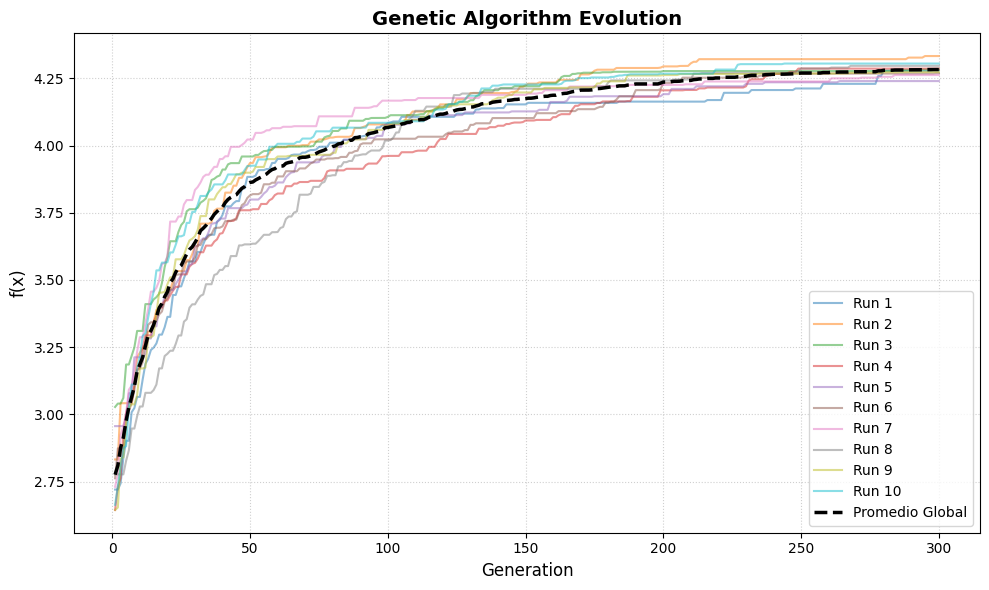


RESUMEN ESTADÍSTICO DE LAS EJECUCIONES
             Métrica    Valor
      Mejor (f_best) 4.333269
      Peor (f_worst) 4.240085
Promedio (f_average) 4.283118
Desv. Estándar (std) 0.024001

MEJOR SOLUCIÓN (Run 2)
• Fitness alcanzado f(x): 4.333269
• Nº de recursos elegidos: 77 de 217
• Índices de los recursos seleccionados: [3, 5, 7, 11, 12, 17, 19, 20, 25, 27, 28, 32, 34, 37, 38, 40, 41, 43, 49, 52, 53, 54, 57, 59, 60, 62, 67, 70, 72, 73, 74, 75, 83, 85, 86, 90, 91, 92, 94, 99, 100, 105, 106, 111, 115, 117, 123, 127, 131, 134, 137, 141, 142, 146, 147, 148, 149, 151, 152, 155, 160, 173, 177, 180, 186, 187, 188, 189, 190, 191, 201, 203, 209, 210, 212, 213, 214]


In [6]:
# Extraer las curvas de convergencia (convertidas a maximización)
convergence_curves = []
for hist in all_histories:
    # Extraemos el fitness del mejor individuo de cada generación y le cambiamos el signo
    gen_fitness = [-evals.opt[0].F[0] for evals in hist]
    convergence_curves.append(gen_fitness)

convergence_matrix = np.array(convergence_curves) # Forma: (runs, n_max_gen)

# Gráfico de evolución 
plt.figure(figsize=(10, 6))
generations = np.arange(1, convergence_matrix.shape[1] + 1)

# Dibujar cada una de las 10 ejecuciones
for r in range(runs):
    plt.plot(generations, convergence_matrix[r, :], alpha=0.5, linewidth=1.5, label=f'Run {r+1}')

# Dibujar la curva promedio global destacada
mean_curve = np.mean(convergence_matrix, axis=0)
plt.plot(generations, mean_curve, color='black', linewidth=2.5, linestyle='--', label='Promedio Global')

plt.title('Genetic Algorithm Evolution', fontsize=14, fontweight='bold')
plt.xlabel('Generation', fontsize=12)
plt.ylabel('f(x)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('EvolutionGA.png', dpi=300, bbox_inches='tight')
plt.show()

# Tabla resumen de estadísticos
f_best = np.max(best_fitness_per_run)
f_worst = np.min(best_fitness_per_run)
f_average = np.mean(best_fitness_per_run)
f_std = np.std(best_fitness_per_run)

df_stats = pd.DataFrame({
    'Métrica': ['Mejor (f_best)', 'Peor (f_worst)', 'Promedio (f_average)', 'Desv. Estándar (std)'],
    'Valor': [f_best, f_worst, f_average, f_std]
})

print("\n" + "="*55)
print("RESUMEN ESTADÍSTICO DE LAS EJECUCIONES")
print("="*55)
print(df_stats.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("="*55)

# Mejor solución de la mejor run
best_run_idx = np.argmax(best_fitness_per_run)
best_x = best_solutions_per_run[best_run_idx]
selected_indices = np.where(best_x)[0].tolist()
print(f"\n" + "="*55)
print(f"MEJOR SOLUCIÓN (Run {best_run_idx + 1})")
print("="*55)
print(f"• Fitness alcanzado f(x): {best_fitness_per_run[best_run_idx]:.6f}")
print(f"• Nº de recursos elegidos: {len(selected_indices)} de {len(best_x)}")
print(f"• Índices de los recursos seleccionados: {selected_indices}")
print("="*55)